In [9]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sys
import joblib
import os
import platform
import psutil
%matplotlib inline
from pathlib import Path
import json
import hashlib
import subprocess
import platform
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, accuracy_score, 
                            roc_curve, precision_recall_curve)
from pathlib import Path
from app.preprocessing import validate_data
from app.training import (split_data, build_pipeline, train_model, choose_threshold,save_pipeline)
from app.prediction import (load_pipeline, predict_transactions)
from app.evaluation import (evaluate_predictions,generate_report)
from datetime import datetime, timezone



In [10]:
# Charger le fichier CSV
df = pd.read_csv("data/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
print("Dimensions du jeu de données :", df.shape)
print("Nombre de transactions :", df.shape[0])
print("Nombre de variables :", df.shape[1])
df.info()

Dimensions du jeu de données : (284807, 31)
Nombre de transactions : 284807
Nombre de variables : 31
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 

### PARTIE II — Tests unitaires et qualité des données
### Activité 2. Tester les fonctions critiques du pipeline

In [12]:
%cd D:/AI-TestGuard
!python -m pytest tests/test_preprocessing.py -v

D:\AI-TestGuard
============================= test session starts =============================
platform win32 -- Python 3.14.10, pytest-9.2.0, pluggy-1.7.0 -- D:\AI-TestGuard\.venvtest\Scripts\python.exe
cachedir: .pytest_cache
rootdir: D:\AI-TestGuard
plugins: platformdirs-4.14.5, anyio-4.16.0, cov-7.1.0
collecting ... collected 14 items

tests/test_preprocessing.py::test_required_columns_present PASSED        [  7%]
tests/test_preprocessing.py::test_missing_column PASSED                  [ 14%]
tests/test_preprocessing.py::test_duplicate_column PASSED                [ 21%]
tests/test_preprocessing.py::test_missing_values PASSED                  [ 28%]
tests/test_preprocessing.py::test_infinite_values PASSED                 [ 35%]
tests/test_preprocessing.py::test_empty_data PASSED                      [ 42%]
tests/test_preprocessing.py::test_incorrect_variable_type PASSED         [ 50%]
tests/test_preprocessing.py::test_invalid_target_values PASSED           [ 57%]
tests/test_prepro

## PARTIE III — Évaluation des performances du modèle
### Activité 3. Mesurer et analyser les erreurs de classification

- ### Séparer les données en trois ensembles

In [13]:
X = df.drop(columns=["Class"])
y = df["Class"]
# séparation en 70 % entraînement
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
# séparation  en 15 % validation et 15 % test
X_val, X_test, y_val, y_test = train_test_split(X_temp,  y_temp, test_size=0.50, random_state=42, stratify=y_temp)
print("Dimensions des ensembles :")
print("Entraînement :", X_train.shape)
print("Validation   :", X_val.shape)
print("Test         :", X_test.shape)
print("\nNombre de fraudes dans chaque ensemble :")
print("Entraînement :", y_train.sum())
print("Validation   :", y_val.sum())
print("Test         :", y_test.sum())

Dimensions des ensembles :
Entraînement : (199364, 30)
Validation   : (42721, 30)
Test         : (42722, 30)

Nombre de fraudes dans chaque ensemble :
Entraînement : 344
Validation   : 74
Test         : 74


- ### Préparer les modèles

In [14]:
preprocessor = ColumnTransformer(transformers=[("standardisation", StandardScaler(), ["Time", "Amount"])], remainder="passthrough")
# Modèle de régression logistique
logistic_model = Pipeline([("preprocessing", preprocessor), ("model", LogisticRegression( max_iter=1000, class_weight="balanced", random_state=42))])
# Modèle d'arbre de décision
tree_model = Pipeline([("preprocessing", preprocessor), ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, class_weight="balanced",
        random_state=42))])
print("Les deux modèles sont préparés avec succes.")

Les deux modèles sont préparés avec succes.


- ### Entraîner les deux modèles

In [15]:
logistic_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
print("Les deux modèles ont été entraînés avec succès.")

Les deux modèles ont été entraînés avec succès.


- ### Définir les critères métier et choisir les seuils

In [16]:
def choose_threshold(model, X_validation, y_validation, min_recall=0.80, max_fpr=0.01):
    probabilities = model.predict_proba(X_validation)[:, 1]
    results = []
    # Tester plusieurs seuils sur les données de validation
    for threshold in np.linspace(0.01, 0.99, 99):
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_validation, predictions, labels=[0, 1]).ravel()
        precision = precision_score(y_validation, predictions, zero_division=0)
        recall = recall_score(y_validation, predictions, zero_division=0)
        f1 = f1_score(y_validation, predictions, zero_division=0)
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
        results.append({"threshold": threshold, "precision": precision, "recall": recall, "f1": f1, "fpr": fpr})
    # Garder les seuils qui respectent les critères métier
    acceptable = [
        result for result in results
        if result["recall"] >= min_recall
        and result["fpr"] <= max_fpr]
    if acceptable:
        best = max(acceptable, key=lambda result: result["precision"])
        print("le seuil respectant les critères a été trouvé.")
    else:
        best = max(results, key=lambda result: result["f1"])
        print("Attention : aucun seuil ne respecte les deux critères.")
        print("Le seuil affiché maximise le F1-score sur la validation.")
    return best

# Application aux modeles
threshold_logistic = choose_threshold(logistic_model, X_val, y_val)
threshold_tree = choose_threshold(tree_model, X_val, y_val)
print("\nSeuil retenu pour la régression logistique :")
print(threshold_logistic)
print("\nSeuil retenu pour l'arbre de décision :")
print(threshold_tree)

le seuil respectant les critères a été trouvé.
le seuil respectant les critères a été trouvé.

Seuil retenu pour la régression logistique :
{'threshold': np.float64(0.98), 'precision': 0.5126050420168067, 'recall': 0.8243243243243243, 'f1': 0.6321243523316062, 'fpr': np.float64(0.0013600018758646564)}

Seuil retenu pour l'arbre de décision :
{'threshold': np.float64(0.9400000000000001), 'precision': 0.31413612565445026, 'recall': 0.8108108108108109, 'f1': 0.4528301886792453, 'fpr': np.float64(0.0030717283747977585)}


- ### Créer la fonction d'évaluation

In [17]:
def evaluate_model(model, X_test, y_test, threshold):
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    # Matrice de confusion
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    # Calcul des métriques
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
    accuracy = accuracy_score(y_test, y_pred)
    print("Matrice de confusion :")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
    print("\nDétail de la matrice :")
    print("Vrais négatifs (TN) :", tn)
    print("Faux positifs (FP)  :", fp)
    print("Faux négatifs (FN)  :", fn)
    print("Vrais positifs (TP) :", tp)
    print("\nMétriques de performance :")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")
    print(f"PR-AUC    : {pr_auc:.4f}")
    print(f"FPR       : {fpr:.4f}")
    print(f"FNR       : {fnr:.4f}")
    return {"y_pred": y_pred, "y_proba": y_proba, "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Accuracy": accuracy, "Precision": precision,
        "Recall": recall, "F1-score": f1, "ROC-AUC": roc_auc, "PR-AUC": pr_auc, "FPR": fpr, "FNR": fnr}

# Evaluation 
print("-" * 55)
print("ÉVALUATION DE LA RÉGRESSION LOGISTIQUE")

results_logistic = evaluate_model(logistic_model, X_test, y_test, threshold_logistic["threshold"])
print("\n" + "-" * 55)
print("ÉVALUATION DE L'ARBRE DE DÉCISION")
results_tree = evaluate_model(tree_model, X_test, y_test,  threshold_tree["threshold"])

-------------------------------------------------------
ÉVALUATION DE LA RÉGRESSION LOGISTIQUE
Matrice de confusion :
[[42610    38]
 [   12    62]]

Détail de la matrice :
Vrais négatifs (TN) : 42610
Faux positifs (FP)  : 38
Faux négatifs (FN)  : 12
Vrais positifs (TP) : 62

Métriques de performance :
Accuracy  : 0.9988
Precision : 0.6200
Recall    : 0.8378
F1-score  : 0.7126
ROC-AUC   : 0.9675
PR-AUC    : 0.7904
FPR       : 0.0009
FNR       : 0.1622

-------------------------------------------------------
ÉVALUATION DE L'ARBRE DE DÉCISION
Matrice de confusion :
[[42515   133]
 [   15    59]]

Détail de la matrice :
Vrais négatifs (TN) : 42515
Faux positifs (FP)  : 133
Faux négatifs (FN)  : 15
Vrais positifs (TP) : 59

Métriques de performance :
Accuracy  : 0.9965
Precision : 0.3073
Recall    : 0.7973
F1-score  : 0.4436
ROC-AUC   : 0.9022
PR-AUC    : 0.4802
FPR       : 0.0031
FNR       : 0.2027


- ### Construire le tableau comparatif

In [18]:
comparison = pd.DataFrame([{"Modèle": "Régression logistique", "Seuil": threshold_logistic["threshold"],**{key: results_logistic[key]
                for key in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC", "FPR", "FNR"]}},{"Modèle": "Arbre de décision",
            "Seuil": threshold_tree["threshold"],**{key: results_tree[key]
                for key in ["Accuracy", "Precision", "Recall", "F1-score","ROC-AUC", "PR-AUC", "FPR", "FNR"]}}])
comparison.round(4)

,Modèle,Seuil,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FPR,FNR
0,Régression logistique,0.98,0.9988,0.6200,0.8378,0.7126,0.9675,0.7904,0.0009,0.1622
1,Arbre de décision,0.94,0.9965,0.3073,0.7973,0.4436,0.9022,0.4802,0.0031,0.2027


- ### Matrices de confusion

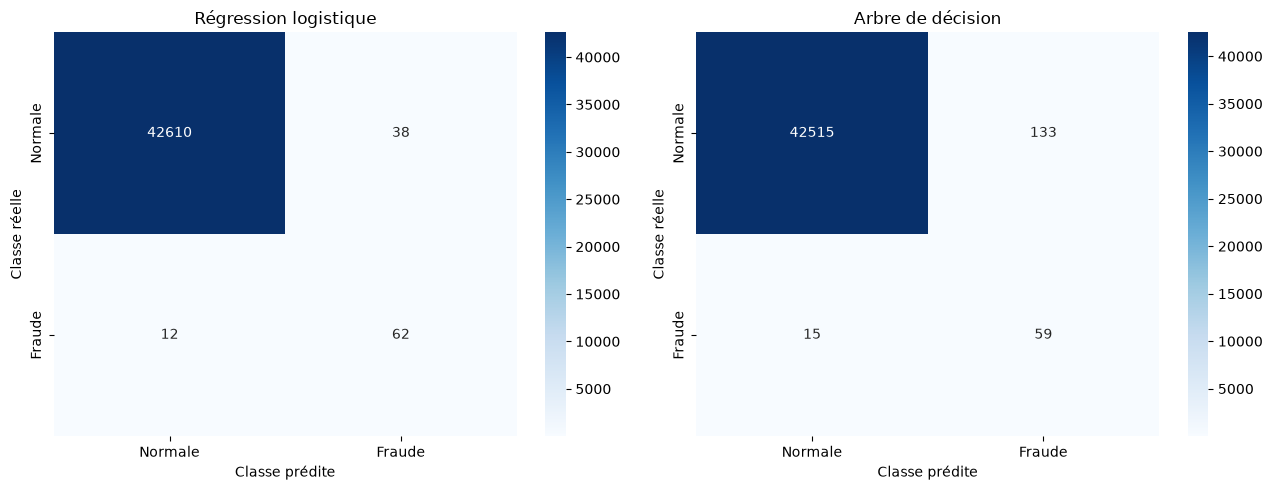

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
models_results = [("Régression logistique", results_logistic), ("Arbre de décision", results_tree)]
for ax, (name, result) in zip(axes, models_results):
    cm = confusion_matrix(y_test, result["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normale", "Fraude"], yticklabels=["Normale", "Fraude"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

- ### Visualiser les courbes ROC et précision-rappel

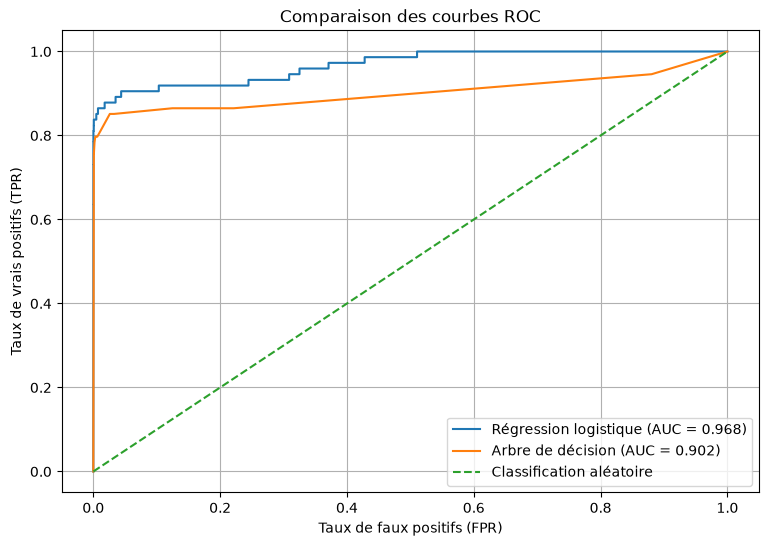

In [20]:
probabilities = {"Régression logistique": results_logistic["y_proba"], "Arbre de décision": results_tree["y_proba"]}
# graphique courbes ROC
plt.figure(figsize=(9, 6))
for name, y_proba in probabilities.items():
    fpr_curve, tpr_curve, thresholds = roc_curve(y_test, y_proba)
    auc_value = roc_auc_score(y_test, y_proba)
    plt.plot(fpr_curve, tpr_curve, label=f"{name} (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Classification aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Comparaison des courbes ROC")
plt.legend()
plt.grid()
plt.show()

- ### courbe précision-rappel

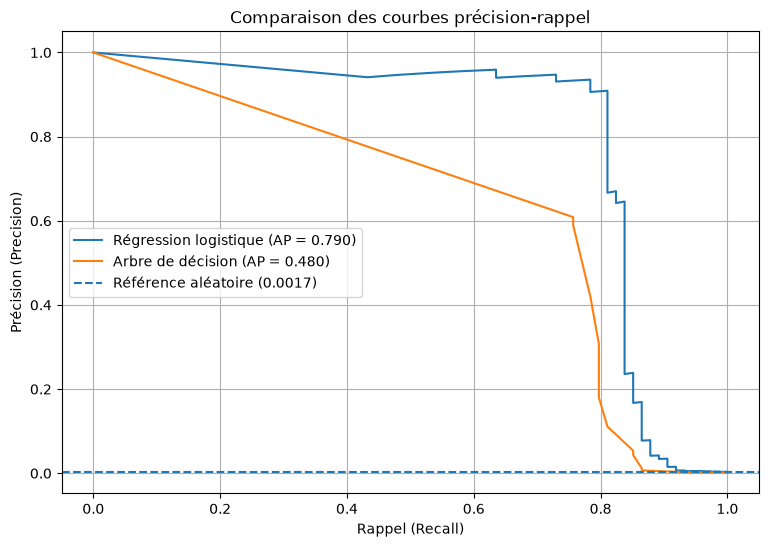

In [21]:
plt.figure(figsize=(9, 6))
for name, y_proba in probabilities.items():
    precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_proba)
    ap_value = average_precision_score(y_test, y_proba)
    plt.plot(recall_curve, precision_curve, label=f"{name} (AP = {ap_value:.3f})")
baseline = y_test.mean()
plt.axhline(baseline, linestyle="--", label=f"Référence aléatoire ({baseline:.4f})")
plt.xlabel("Rappel (Recall)")
plt.ylabel("Précision (Precision)")
plt.title("Comparaison des courbes précision-rappel")
plt.legend()
plt.grid()
plt.show()

- ### Analyser les faux positifs et les faux négatifs

In [22]:
errors_logistic = X_test.copy()
errors_logistic["Classe_reelle"] = y_test
errors_logistic["Classe_predite"] = results_logistic["y_pred"]
false_positives_logistic = errors_logistic[
    (errors_logistic["Classe_reelle"] == 0) &
    (errors_logistic["Classe_predite"] == 1)]

false_negatives_logistic = errors_logistic[
    (errors_logistic["Classe_reelle"] == 1) &
    (errors_logistic["Classe_predite"] == 0)]

print("Régression logistique")
print("Nombre de faux positifs :", len(false_positives_logistic))
print("Nombre de faux négatifs :", len(false_negatives_logistic))
print("\nExemples de faux positifs :")
display(false_positives_logistic.head())
print("\nExemples de faux négatifs :")
display(false_negatives_logistic.head())

Régression logistique
Nombre de faux positifs : 38
Nombre de faux négatifs : 12

Exemples de faux positifs :


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Classe_reelle,Classe_predite
8464,11347.0,1.261630,2.797779,-5.458663,3.844880,5.435051,1.844395,1.203394,0.323753,-1.416101,...,-0.972494,-0.592696,0.280911,1.572414,0.491744,-0.025573,0.152650,1.00,0,1
219953,141953.0,1.159306,3.309209,-4.904274,5.735690,2.498088,-1.379706,0.884800,0.233308,-2.667097,...,-0.540243,-0.009830,-1.100836,-0.227338,0.476402,0.015396,-0.167612,0.77,0,1
153427,99036.0,1.918820,1.866106,-2.450148,4.620473,1.579175,-1.232096,0.548805,-0.393915,-0.177228,...,-0.124809,-0.014644,-0.427398,0.129552,0.097009,-0.000422,0.055532,0.00,0,1
272634,165191.0,-1.632074,3.762549,-3.155568,1.404202,2.166054,-0.195328,-0.486817,-6.704450,-1.316302,...,-2.064895,-0.314638,-0.941216,2.721087,0.278160,0.337812,0.278961,1.00,0,1
148998,90426.0,0.212824,2.709401,-1.337772,5.151580,2.345631,-0.027058,1.309770,-0.231652,-1.227225,...,-0.459387,-0.197807,0.046060,-0.519172,0.317994,0.232335,0.305991,15.13,0,1



Exemples de faux négatifs :


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Classe_reelle,Classe_predite
254395,156710.0,0.202402,1.176270,0.346379,2.882138,1.407133,-0.504355,1.438537,-0.395603,-1.555142,...,0.841230,-0.370157,-0.026012,0.491954,0.234576,-0.279788,-0.331933,7.59,1,0
157918,110617.0,-1.101035,-1.674928,-0.573388,5.617556,0.765556,0.440607,1.934740,-1.019788,-0.193244,...,-0.208823,0.344833,1.091435,-0.686513,0.075809,0.033865,-0.832855,635.10,1,0
249239,154309.0,-0.082983,-3.935919,-2.616709,0.163310,-1.400952,-0.809419,1.501580,-0.471000,1.519743,...,-0.182305,-0.921017,0.111635,-0.071622,-1.125881,-0.170947,0.126221,1096.99,1,0
192687,129808.0,1.522080,-0.519429,-2.581685,0.774741,0.206722,-1.431020,0.757011,-0.444418,0.997921,...,-0.211678,-0.247452,-0.279472,0.239646,-0.508398,-0.015551,0.041881,276.17,1,0
100623,67571.0,-0.758469,-0.045410,-0.168438,-1.313275,-1.901763,0.739433,3.071892,-0.483422,0.618203,...,0.397224,0.072229,-0.242276,0.560916,-0.540955,0.150606,-0.117140,549.06,1,0


- ### Analyser les faux positifs et les faux négatifs de l'arbre de decision

In [23]:
errors_tree = X_test.copy()
errors_tree["Classe_reelle"] = y_test
errors_tree["Classe_predite"] = results_tree["y_pred"]
false_positives_tree = errors_tree[
    (errors_tree["Classe_reelle"] == 0) &
    (errors_tree["Classe_predite"] == 1)]
false_negatives_tree = errors_tree[
    (errors_tree["Classe_reelle"] == 1) &
    (errors_tree["Classe_predite"] == 0)]

print("Arbre de décision")
print("Nombre de faux positifs :", len(false_positives_tree))
print("Nombre de faux négatifs :", len(false_negatives_tree))

Arbre de décision
Nombre de faux positifs : 133
Nombre de faux négatifs : 15


- ### Définir les critères d'acceptation métier

In [24]:
def check_acceptance(result):
    criteria = {"Recall >= 0.80": result["Recall"] >= 0.80, "FPR <= 0.01": result["FPR"] <= 0.01, "Precision >= 0.50": result["Precision"] >= 0.50,
        "F1-score >= 0.60": result["F1-score"] >= 0.60}
    for criterion, passed in criteria.items():
        print(f"{criterion} : {'RESPECTÉ' if passed else 'NON RESPECTÉ'}")
    return all(criteria.values())
print("RÉGRESSION LOGISTIQUE")
accepted_logistic = check_acceptance(results_logistic)
print("\nARBRE DE DÉCISION")
accepted_tree = check_acceptance(results_tree)

RÉGRESSION LOGISTIQUE
Recall >= 0.80 : RESPECTÉ
FPR <= 0.01 : RESPECTÉ
Precision >= 0.50 : RESPECTÉ
F1-score >= 0.60 : RESPECTÉ

ARBRE DE DÉCISION
Recall >= 0.80 : NON RESPECTÉ
FPR <= 0.01 : RESPECTÉ
Precision >= 0.50 : NON RESPECTÉ
F1-score >= 0.60 : NON RESPECTÉ


### PARTIE IV — Tests d'intégration et prévention des fuites de données
## 4.1.	 Tester le pipeline de bout en bout

- ### Tester le pipeline

In [25]:
print("-" * 75)
print("TEST DU PIPELINE ET DETECTION DE FRAUDE")
print("-" * 75)
PROJECT_DIR = Path("D:/AI-TestGuard")
DATA_PATH = PROJECT_DIR / "data" / "creditcard.csv"
MODEL_PATH = PROJECT_DIR / "reports" / "pipeline_fraude.joblib"
REPORT_PATH = PROJECT_DIR / "reports" / "rapport_integration.csv"
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

# Suivi des 12 étapes
etapes = ["Chargement des données", "Validation du schéma", "Séparation des données", "Entraînement du modèle", "Prévention des fuites", "Prétraitement",
    "Choix du seuil", "Sauvegarde du pipeline", "Rechargement du pipeline", "Reproductibilité", "Evaluation", "Rapport des métriques"]
statuts = {etape: "NOT RUN" for etape in etapes}

def valider_etape(nom):
    statuts[nom] = "PASSED"
    
def afficher_resume():
    print("\n" + "=" * 75)
    print("TEST D'INTEGRATION")
    print("=" * 75)
    for nom, statut in statuts.items():
        print(f"{nom:<38} : {statut}")
    total = len(statuts)
    reussies = sum(s == "PASSED" for s in statuts.values())
    echouees = sum(s == "FAILED" for s in statuts.values())
    non_executees = sum(s == "NOT RUN" for s in statuts.values())
    print("-" * 75)
    print("Total des étapes :", total)
    print("Réussies         :", reussies)
    print("Échouées         :", echouees)
    print("Non exécutées    :", non_executees)
    if reussies == total:
        print("\nRESULTAT GLOBAL : PASSED")
    else:
        print("\nRESULTAT GLOBAL : FAILED")
    print("=" * 75)

# ================================================================
# EXECUTION DU PIPELINE
# ================================================================
try:
    print("\n1. CHARGEMENT DES DONNEES")
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Fichier introuvable : {DATA_PATH}")
    df = pd.read_csv(DATA_PATH)
    print("Fichier chargé avec succès.")
    print("Dimensions :", df.shape)
    valider_etape("Chargement des données")

    print("\n2. VALIDATION DU SCHEMA")
    validate_data(df)
    print("Schéma valide.")
    print("Colonnes attendues présentes.")
    print("Aucune valeur manquante.")
    print("Aucune valeur infinie.")
    print("Variable cible valide.")
    valider_etape("Validation du schéma")

    # 3. REPARTITION DES CLASSES
    print("\n3. REPARTITION DES CLASSES")
    print(df["Class"].value_counts())
    print("\nPourcentages :")
    print(df["Class"].value_counts(normalize=True) * 100)

    # 4. SEPARATION DES DONNEES
    print("\n4. SEPARATION DES DONNEES")
    (X_train, X_valid, X_test, y_train, y_valid, y_test) = split_data(df)
    print("Entraînement :", X_train.shape)
    print("Validation  :", X_valid.shape)
    print("Test        :", X_test.shape)
    assert len(X_train) + len(X_valid) + len(X_test) == len(df)
    print("Données séparées avec succès.")
    valider_etape("Séparation des données")

    # 5. CONSTRUCTION DU PIPELINE
    print("\n5. CONSTRUCTION DU PIPELINE")
    pipeline = build_pipeline()
    print(pipeline)

    # 6. ENTRAINEMENT DU MODELE
    print("\n6. ENTRAINEMENT DU MODELE")
    train_model(pipeline, X_train, y_train)
    print("Modèle entraîné avec succès.")
    valider_etape("Entraînement du modèle")

    # 7. VERIFICATION DU SCALER ET DES FUITES
    print("\n7. VERIFICATION DU SCALER")
    scaler = (pipeline.named_steps["preprocessing"].named_transformers_["scaler"])
    expected_mean = (X_train[["Time", "Amount"]].mean().to_numpy())
    np.testing.assert_allclose(scaler.mean_, expected_mean, rtol=1e-7, atol=1e-7)
    print("Vérification réussie.")
    print("Moyennes apprises par le scaler :", scaler.mean_)
    valider_etape("Prévention des fuites")

    # 8. VERIFICATION DU PRETRAITEMENT
    print("\n8. VERIFICATION DU PRETRAITEMENT")
    X_test_transformed = (pipeline.named_steps["preprocessing"].transform(X_test))
    print("Dimensions après transformation :", X_test_transformed.shape)
    assert X_test_transformed.shape[0] == X_test.shape[0]
    assert X_test_transformed.shape[1] == X_test.shape[1]
    assert np.isfinite(X_test_transformed).all()
    print("Aucune valeur non finie après transformation.")
    valider_etape("Prétraitement")

    # 9. CHOIX DU SEUIL
    print("\n9. CHOIX DU SEUIL")
    threshold = choose_threshold(pipeline, X_valid, y_valid)
    print("Seuil retenu :", threshold)
    assert 0 < threshold < 1
    valider_etape("Choix du seuil")

    # 10. PREDICTIONS AVANT SAUVEGARDE
    print("\n10. PREDICTIONS AVANT SAUVEGARDE")
    probabilities_before = (pipeline.predict_proba(X_test)[:, 1])
    predictions_before = (probabilities_before >= threshold).astype(int)
    print("Nombre de prédictions :",len(predictions_before))

    # 11. SAUVEGARDE DU PIPELINE
    print("\n11. SAUVEGARDE DU PIPELINE")
    save_pipeline(pipeline, threshold, MODEL_PATH)
    assert MODEL_PATH.exists()
    print("Pipeline sauvegardé :", MODEL_PATH)
    valider_etape("Sauvegarde du pipeline")

    # 12. RECHARGEMENT DU PIPELINE
    print("\n12. RECHARGEMENT DU PIPELINE")
    artifact = load_pipeline(MODEL_PATH)
    print("Pipeline rechargé avec succès.")
    valider_etape("Rechargement du pipeline")

    # 13. PREDICTIONS APRES RECHARGEMENT
    print("\n13. PREDICTIONS APRES RECHARGEMENT")
    predictions_after, probabilities_after = (predict_transactions(artifact, X_test))
    print("Prédictions effectuées avec succès.")

    # 14. VERIFICATION DE LA REPRODUCTIBILITE
    print("\n14. VERIFICATION DE LA REPRODUCTIBILITE")
    # Vérifier les probabilités
    np.testing.assert_allclose(probabilities_before, probabilities_after, rtol=1e-7, atol=1e-7)
    print("Les probabilités sont identiques.")
    # Vérifier les classes
    np.testing.assert_array_equal(predictions_before, predictions_after)
    print("Les classes prédites sont identiques.")
    print("Reproductibilité confirmée.")
    valider_etape("Reproductibilité")

    # 15. EVALUATION DU MODELE
    print("\n15. EVALUATION DU MODELE")
    results = evaluate_predictions(y_test, predictions_after, probabilities_after)
    report = generate_report(results)
    valider_etape("Evaluation")

    # 16. SAUVEGARDE DU RAPPORT
    print("\n16. SAUVEGARDE DU RAPPORT")
    report.to_csv(REPORT_PATH, index=False, encoding="utf-8-sig")
    assert REPORT_PATH.exists()
    print("Rapport enregistré :", REPORT_PATH)
    valider_etape("Rapport des métriques")

except Exception as error:
    for nom in etapes:
        if statuts[nom] == "NOT RUN":
            statuts[nom] = "FAILED"
            break
    print("\nERREUR DURANT LE TEST D'INTEGRATION")
    print(type(error).__name__, ":", error)
finally:
    afficher_resume()

---------------------------------------------------------------------------
TEST DU PIPELINE ET DETECTION DE FRAUDE
---------------------------------------------------------------------------

1. CHARGEMENT DES DONNEES
Fichier chargé avec succès.
Dimensions : (284807, 31)

2. VALIDATION DU SCHEMA
Schéma valide.
Colonnes attendues présentes.
Aucune valeur manquante.
Aucune valeur infinie.
Variable cible valide.

3. REPARTITION DES CLASSES
Class
0    284315
1       492
Name: count, dtype: int64

Pourcentages :
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

4. SEPARATION DES DONNEES
Entraînement : (199364, 30)
Validation  : (42721, 30)
Test        : (42722, 30)
Données séparées avec succès.

5. CONSTRUCTION DU PIPELINE
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scaler', StandardScaler(),
                                                  ['Time', 'Amount'])])),
     

## PARTIE V — Tests de robustesse et de sensibilité
### 6.1. Tester le comportement sur des données imparfaites

- ### Test de robustesse et de sensibilite

In [26]:
%cd D:/AI-TestGuard
!python -m pytest tests/test_robustness.py -v -s

D:\AI-TestGuard
============================= test session starts =============================
platform win32 -- Python 3.14.10, pytest-9.2.0, pluggy-1.7.0 -- D:\AI-TestGuard\.venvtest\Scripts\python.exe
cachedir: .pytest_cache
rootdir: D:\AI-TestGuard
plugins: platformdirs-4.14.5, anyio-4.16.0, cov-7.1.0
collecting ... collected 8 items

tests/test_robustness.py::test_missing_values_rejected PASSED
tests/test_robustness.py::test_infinite_values_rejected PASSED
tests/test_robustness.py::test_non_numeric_values_rejected PASSED
tests/test_robustness.py::test_extreme_amount_is_processed 
Montant extrême traité avec succès.
PASSED
tests/test_robustness.py::test_limited_perturbation 
Perturbation de Amount : +1 %
Variation moyenne des probabilités : 0.0006025046326925558
Variation maximale : 0.004202997899637517
Nombre de classes modifiées : 30
PASSED
tests/test_robustness.py::test_distribution_shift 
Test de décalage de distribution
Variation moyenne des probabilités : 0.05474116249416959

## PARTIE VI — Validation hors échantillon et non-régression
### Vérifier la généralisation et prévenir les régressions
## 6.1 Validation hors échantillon

- ### Séparer les données et utiliser un jeu d'entraînement, un jeu de validation et un jeu de test.

In [27]:
X_train, X_valid, X_test, y_train, y_valid, y_test = split_data(df)
# Affichage des dimensions
print("Jeu d'entraînement :", X_train.shape)
print("Jeu de validation  :", X_valid.shape)
print("Jeu de test        :", X_test.shape)
# Vérification de la répartition des fraudes
print("\nFraudes dans le jeu d'entraînement :", y_train.sum())
print("Fraudes dans le jeu de validation  :", y_valid.sum())
print("Fraudes dans le jeu de test        :", y_test.sum())

Jeu d'entraînement : (199364, 30)
Jeu de validation  : (42721, 30)
Jeu de test        : (42722, 30)

Fraudes dans le jeu d'entraînement : 344
Fraudes dans le jeu de validation  : 74
Fraudes dans le jeu de test        : 74


- ### Vérification de la répartition des classes

In [28]:
# Fonction pour afficher la répartition des classes
def afficher_repartition(y, nom):
    print(f"\n{nom}")
    print(y.value_counts().sort_index())
    print("\nPourcentages :")
    print((y.value_counts(normalize=True).sort_index() * 100).round(4))

# Afficher la répartition dans chaque ensemble
afficher_repartition(y_train, "ENSEMBLE D'ENTRAÎNEMENT")
afficher_repartition(y_valid, "ENSEMBLE DE VALIDATION")
afficher_repartition(y_test, "ENSEMBLE DE TEST")


ENSEMBLE D'ENTRAÎNEMENT
Class
0    199020
1       344
Name: count, dtype: int64

Pourcentages :
Class
0    99.8275
1     0.1725
Name: proportion, dtype: float64

ENSEMBLE DE VALIDATION
Class
0    42647
1       74
Name: count, dtype: int64

Pourcentages :
Class
0    99.8268
1     0.1732
Name: proportion, dtype: float64

ENSEMBLE DE TEST
Class
0    42648
1       74
Name: count, dtype: int64

Pourcentages :
Class
0    99.8268
1     0.1732
Name: proportion, dtype: float64


- ### Ajuster les hyperparamètres et le seuil de décision à partir des données autorisées.

In [29]:
pipeline = build_pipeline()
pipeline = train_model(pipeline, X_train, y_train)
threshold = choose_threshold(pipeline, X_valid, y_valid)
print("Modèle entraîné avec succès.")
print("Seuil de décision sélectionné :", threshold)

le seuil respectant les critères a été trouvé.
Modèle entraîné avec succès.
Seuil de décision sélectionné : {'threshold': np.float64(0.98), 'precision': 0.5126050420168067, 'recall': 0.8243243243243243, 'f1': 0.6321243523316062, 'fpr': np.float64(0.0013600018758646564)}


- ### Évaluer le modèle sur le jeu de test

In [30]:

# Vérification et récupération du seuil
if isinstance(threshold, dict):
    threshold_value = threshold.get("threshold", threshold.get("best_threshold"))
else:
    threshold_value = threshold

# Vérification du seuil
if not isinstance(threshold_value, (int, float)):
    raise ValueError(f"Le seuil doit être numérique. Valeur reçue : {threshold_value}")

# Création de l'artefact
artifact = {
    "pipeline": pipeline,
    "threshold": float(threshold_value),
    "feature_columns": list(X_train.columns)
}

# Prédictions sur les données de test
predictions_test, probabilities_test = predict_transactions(
    artifact, X_test
)

# Évaluation des prédictions
results_test = evaluate_predictions(
    y_test, predictions_test, probabilities_test
)

# Génération du rapport
rapport_test = generate_report(results_test)


===== RAPPORT D'ÉVALUATION =====
   Métrique       Valeur
   Accuracy     0.998830
  Precision     0.620000
     Recall     0.837838
   F1-score     0.712644
    ROC-AUC     0.967508
PR-AUC (AP)     0.790375
        FPR     0.000891
        FNR     0.162162
         TN 42610.000000
         FP    38.000000
         FN    12.000000
         TP    62.000000


- ### Comparaison des performances et détection du surapprentissage

In [31]:
predictions_train, probabilities_train = predict_transactions(artifact, X_train)
results_train = evaluate_predictions(y_train, predictions_train, probabilities_train)
comparaison = pd.DataFrame({
    "Métrique": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Entraînement": [results_train["Accuracy"], results_train["Precision"], results_train["Recall"], results_train["F1-score"],
        results_train["ROC-AUC"]],
    "Test": [results_test["Accuracy"], results_test["Precision"], results_test["Recall"], results_test["F1-score"], results_test["ROC-AUC"]]})
print(comparaison.round(4))

    Métrique  Entraînement    Test
0   Accuracy        0.9988  0.9988
1  Precision        0.6000  0.6200
2     Recall        0.8547  0.8378
3   F1-score        0.7050  0.7126
4    ROC-AUC        0.9916  0.9675


### 6.2 Tests de non-régression

- ### Enregistrement de la configuration du projet

In [32]:

# Version du code (commit Git)
try:
    code_version = subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        text=True
    ).strip()
except Exception:
    code_version = "non disponible"

# Configuration du modèle
model_parameters = pipeline.get_params()

# Informations sur les bibliothèques et l'environnement
library_versions = {
    "Python": sys.version,
    "Plateforme": platform.platform(),
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit-learn": sklearn.__version__
}

# Graines aléatoires utilisées
random_seeds = {
    "train_test_split": 42,
    "LogisticRegression": 42
}

print("Version du code :", code_version)
print("\nVersions des bibliothèques :")
print(json.dumps(library_versions, indent=4, ensure_ascii=False))

print("\nGraines aléatoires :")
print(random_seeds)

Version du code : non disponible

Versions des bibliothèques :
{
    "Python": "3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]",
    "Plateforme": "Windows-11-10.0.26300-SP0",
    "NumPy": "2.5.4",
    "Pandas": "3.1.1",
    "Scikit-learn": "1.9.1"
}

Graines aléatoires :
{'train_test_split': 42, 'LogisticRegression': 42}


- ### Caractéristiques du jeu de données

In [33]:
# Caractéristiques générales du jeu de données
dataset_info = {
    "nombre_lignes": int(df.shape[0]),
    "nombre_colonnes": int(df.shape[1]),
    "colonnes": list(df.columns),
    "repartition_classes": {
        str(k): int(v)
        for k, v in df["Class"].value_counts().sort_index().items()
    }
}

# Empreinte du jeu de données pour identifier son contenu
dataset_hash = hashlib.sha256(
    pd.util.hash_pandas_object(df, index=True).values.tobytes()
).hexdigest()

dataset_info["empreinte_sha256"] = dataset_hash

print(json.dumps(dataset_info, indent=4, ensure_ascii=False))

{
    "nombre_lignes": 284807,
    "nombre_colonnes": 31,
    "colonnes": [
        "Time",
        "V1",
        "V2",
        "V3",
        "V4",
        "V5",
        "V6",
        "V7",
        "V8",
        "V9",
        "V10",
        "V11",
        "V12",
        "V13",
        "V14",
        "V15",
        "V16",
        "V17",
        "V18",
        "V19",
        "V20",
        "V21",
        "V22",
        "V23",
        "V24",
        "V25",
        "V26",
        "V27",
        "V28",
        "Amount",
        "Class"
    ],
    "repartition_classes": {
        "0": 284315,
        "1": 492
    },
    "empreinte_sha256": "a50681cbd36ee7701e7e1fc464a0db7de5653ea63487ff23805859a06277ebdf"
}


- ### Enregistrement des métriques de référence

In [34]:

# Vérification du seuil de décision
if isinstance(threshold, dict):
    threshold_value = threshold.get(
        "threshold",
        threshold.get("best_threshold")
    )
else:
    threshold_value = threshold

# Vérification du type du seuil
if threshold_value is None or not isinstance(threshold_value, (int, float)):
    raise ValueError(
        f"Seuil invalide : {threshold}"
    )

# Création de l'artefact
artifact = {
    "pipeline": pipeline,
    "threshold": float(threshold_value),
    "feature_columns": list(X_train.columns)
}

# Prédictions sur les données de validation
predictions_valid, probabilities_valid = predict_transactions(
    artifact, X_valid
)

# Évaluation des prédictions
results_valid = evaluate_predictions(
    y_valid, predictions_valid, probabilities_valid
)

# Génération du rapport
rapport_valid = generate_report(results_valid)

# Affichage du rapport
print(rapport_valid)



===== RAPPORT D'ÉVALUATION =====
   Métrique       Valeur
   Accuracy     0.998338
  Precision     0.512605
     Recall     0.824324
   F1-score     0.632124
    ROC-AUC     0.968415
PR-AUC (AP)     0.627525
        FPR     0.001360
        FNR     0.175676
         TN 42589.000000
         FP    58.000000
         FN    13.000000
         TP    61.000000
       Métrique        Valeur
0      Accuracy      0.998338
1     Precision      0.512605
2        Recall      0.824324
3      F1-score      0.632124
4       ROC-AUC      0.968415
5   PR-AUC (AP)      0.627525
6           FPR      0.001360
7           FNR      0.175676
8            TN  42589.000000
9            FP     58.000000
10           FN     13.000000
11           TP     61.000000


- ###  Création et sauvegarde de la baseline

In [35]:

# ============================================================
# ACTIVITÉ : CRÉATION ET SAUVEGARDE DE LA BASELINE
# Projet : AI-TestGuard
# ============================================================

# 1. Importation des bibliothèques
import numpy as np
import pandas as pd
import sklearn
import sys
import json

from pathlib import Path


# 2. Vérification des variables nécessaires
variables_requises = [
    "y_valid",
    "predictions_valid",
    "probabilities_valid",
    "threshold"
]

for variable in variables_requises:
    if variable not in globals():
        raise NameError(
            f"La variable '{variable}' n'est pas définie. "
            "Exécute d'abord les cellules précédentes."
        )


# 3. Évaluation des performances de la baseline
baseline_metrics = evaluate_predictions(
    y_valid,
    predictions_valid,
    probabilities_valid
)


# 4. Affichage des métriques
print("=" * 60)
print("       PERFORMANCE DE LA BASELINE")
print("=" * 60)

baseline_report = generate_report(baseline_metrics)

print(baseline_report)


# 5. Extraction du seuil de décision
threshold_value = float(threshold["threshold"])


# 6. Préparation des paramètres du modèle
# Utilisation des paramètres réels si le modèle existe
if "model" in globals() and hasattr(model, "get_params"):
    parameters_to_save = model.get_params()
else:
    parameters_to_save = {
        "nom_modele": "AI-TestGuard - Baseline",
        "type": "Modèle de détection de fraude"
    }


# 7. Versions des bibliothèques utilisées
library_versions = {
    "python": sys.version,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__
}


# 8. Graines aléatoires utilisées
random_seeds = {
    "random_state": 42
}


# 9. Informations sur le jeu de données
dataset_info = {
    "nombre_observations_validation": int(len(y_valid)),
    "nombre_predictions": int(len(predictions_valid)),
    "nombre_variables": (
        int(X.shape[1]) if "X" in globals() else None
    )
}


# 10. Création des métadonnées
baseline_metadata = {
    "nom_modele": "AI-TestGuard - Baseline",

    "parametres_modele": parameters_to_save,

    "versions_bibliotheques": library_versions,

    "graines_aleatoires": random_seeds,

    "jeu_donnees": dataset_info,

    "seuil_decision": threshold_value,

    "metriques_validation": {
        key: (
            float(value)
            if np.isfinite(value)
            else None
        )
        for key, value in baseline_metrics.items()
        if isinstance(value, (int, float, np.number))
    }
}


print("\nMétadonnées de la baseline créées avec succès.")


# 11. Création du dossier de sauvegarde
baseline_dir = Path("artifacts/baseline")

baseline_dir.mkdir(
    parents=True,
    exist_ok=True
)


# 12. Sauvegarde des métadonnées au format JSON
baseline_path = baseline_dir / "baseline_metadata.json"

with open(baseline_path, "w", encoding="utf-8") as fichier:

    json.dump(
        baseline_metadata,
        fichier,
        indent=4,
        ensure_ascii=False
    )


# 13. Affichage des informations de sauvegarde
print("\n" + "=" * 60)
print("       SAUVEGARDE DE LA BASELINE")
print("=" * 60)

print("Fichier sauvegardé :", baseline_path)

print("Sauvegarde terminée avec succès.")


# 14. Vérification de l'existence du fichier
if baseline_path.exists():

    print("\nFichier trouvé :", baseline_path)

    # Relecture du fichier JSON
    with open(baseline_path, "r", encoding="utf-8") as fichier:

        baseline_saved = json.load(fichier)

    # Affichage des informations enregistrées
    print("\nNom du modèle :",
          baseline_saved["nom_modele"])

    print("Seuil de décision :",
          baseline_saved["seuil_decision"])

    print("\nMétriques de validation :")

    for metrique, valeur in baseline_saved[
        "metriques_validation"
    ].items():

        print(f"{metrique} : {valeur}")

    print("\n" + "=" * 60)
    print("SAUVEGARDE ET VÉRIFICATION RÉUSSIES")
    print("=" * 60)

else:

    print("Erreur : fichier de baseline introuvable.")


       PERFORMANCE DE LA BASELINE

===== RAPPORT D'ÉVALUATION =====
   Métrique       Valeur
   Accuracy     0.998338
  Precision     0.512605
     Recall     0.824324
   F1-score     0.632124
    ROC-AUC     0.968415
PR-AUC (AP)     0.627525
        FPR     0.001360
        FNR     0.175676
         TN 42589.000000
         FP    58.000000
         FN    13.000000
         TP    61.000000
       Métrique        Valeur
0      Accuracy      0.998338
1     Precision      0.512605
2        Recall      0.824324
3      F1-score      0.632124
4       ROC-AUC      0.968415
5   PR-AUC (AP)      0.627525
6           FPR      0.001360
7           FNR      0.175676
8            TN  42589.000000
9            FP     58.000000
10           FN     13.000000
11           TP     61.000000

Métadonnées de la baseline créées avec succès.

       SAUVEGARDE DE LA BASELINE
Fichier sauvegardé : artifacts\baseline\baseline_metadata.json
Sauvegarde terminée avec succès.

Fichier trouvé : artifacts\baseline\ba

- ### Chargement de la baseline

In [36]:

import json
from pathlib import Path

# Chemin du fichier de la baseline
baseline_path = Path("artifacts/baseline/baseline_metadata.json")

# Vérification de l'existence du fichier
if not baseline_path.exists():
    raise FileNotFoundError(
        f"Fichier de baseline introuvable : {baseline_path}"
    )

# Chargement des métadonnées
with open(baseline_path, "r", encoding="utf-8") as fichier:
    baseline_loaded = json.load(fichier)

# Affichage des informations chargées
print("===== CHARGEMENT DE LA BASELINE =====")

print("Nom du modèle :", baseline_loaded["nom_modele"])
print("Seuil de décision :", baseline_loaded["seuil_decision"])

print("\nMétriques de validation :")

for metrique, valeur in baseline_loaded["metriques_validation"].items():
    print(f"{metrique} : {valeur}")

print("\nBaseline chargée avec succès.")


===== CHARGEMENT DE LA BASELINE =====
Nom du modèle : AI-TestGuard - Baseline
Seuil de décision : 0.98

Métriques de validation :
Accuracy : 0.9983380538845065
Precision : 0.5126050420168067
Recall : 0.8243243243243243
F1-score : 0.6321243523316062
ROC-AUC : 0.9684146535449089
PR-AUC (AP) : 0.6275251631550335
FPR : 0.0013600018758646564
FNR : 0.17567567567567569
TN : 42589.0
FP : 58.0
FN : 13.0
TP : 61.0

Baseline chargée avec succès.


- ### Comparaison des performances et détection des régressions

In [37]:
# 1. Récupération des métriques de la baseline
baseline_metrics = baseline_loaded["metriques_validation"]

# 2. Récupération des métriques du modèle actuel
# Attention : results_valid doit correspondre au modèle que tu souhaites tester.
current_metrics = results_valid

# 3. Définition des métriques à comparer
higher_is_better = [
    "Accuracy", "accuracy",
    "Precision", "precision",
    "Recall", "recall",
    "F1-score", "f1",
    "ROC-AUC", "roc_auc",
    "PR-AUC (AP)", "pr_auc"
]

lower_is_better = [
    "FPR", "fpr",
    "FNR", "fnr"
]

# 4. Comparaison des performances
comparison = []

for metric in baseline_metrics:

    if metric not in current_metrics:
        continue

    baseline_value = baseline_metrics[metric]
    current_value = current_metrics[metric]

    if not isinstance(baseline_value, (int, float, np.number)):
        continue

    if not isinstance(current_value, (int, float, np.number)):
        continue

    if not np.isfinite(baseline_value) or not np.isfinite(current_value):
        continue

    difference = current_value - baseline_value

    if metric in higher_is_better:
        status = "Amélioration" if difference > 0 else (
            "Régression" if difference < -0.01 else "Stable"
        )

    elif metric in lower_is_better:
        status = "Amélioration" if difference < 0 else (
            "Régression" if difference > 0.01 else "Stable"
        )
    else:
        continue

    comparison.append({
        "Métrique": metric,
        "Baseline": baseline_value,
        "Modèle actuel": current_value,
        "Écart": difference,
        "Statut": status
    })

# 5. Affichage du tableau comparatif
comparison_df = pd.DataFrame(comparison)

print("===== COMPARAISON DES PERFORMANCES =====")
display(comparison_df)

# 6. Détection des régressions
regressions = comparison_df[
    comparison_df["Statut"] == "Régression"
]

if len(regressions) > 0:
    print("\nALERTE : Des régressions ont été détectées !")
    display(regressions)
else:
    print("\nAucune régression significative détectée.")

# 7. Résumé
print("\n===== BILAN =====")
print("Nombre de métriques comparées :", len(comparison_df))
print("Améliorations :", 
      (comparison_df["Statut"] == "Amélioration").sum())
print("Régressions :", len(regressions))
print("Métriques stables :", 
      (comparison_df["Statut"] == "Stable").sum())


===== COMPARAISON DES PERFORMANCES =====


,Métrique,Baseline,Modèle actuel,Écart,Statut
0,Accuracy,0.998338,0.998338,0.0,Stable
1,Precision,0.512605,0.512605,0.0,Stable
2,Recall,0.824324,0.824324,0.0,Stable
3,F1-score,0.632124,0.632124,0.0,Stable
4,ROC-AUC,0.968415,0.968415,0.0,Stable
5,PR-AUC (AP),0.627525,0.627525,0.0,Stable
6,FPR,0.001360,0.001360,0.0,Stable
7,FNR,0.175676,0.175676,0.0,Stable



Aucune régression significative détectée.

===== BILAN =====
Nombre de métriques comparées : 8
Améliorations : 0
Régressions : 0
Métriques stables : 8


- ### Génération du rapport de non-régression

In [38]:
# 1. Préparation du bilan
nombre_ameliorations = int(
    (comparison_df["Statut"] == "Amélioration").sum()
)

nombre_regressions = int(
    (comparison_df["Statut"] == "Régression").sum()
)

nombre_stables = int(
    (comparison_df["Statut"] == "Stable").sum()
)

# 2. Détermination du statut global
statut_global = (
    "ÉCHEC - RÉGRESSIONS DÉTECTÉES"
    if nombre_regressions > 0
    else "SUCCÈS - AUCUNE RÉGRESSION DÉTECTÉE"
)

# 3. Création du rapport
rapport_non_regression = {
    "nom_projet": "AI-TestGuard",
    "date_generation": datetime.now().isoformat(),
    "type_rapport": "Rapport de non-régression",
    "statut_global": statut_global,
    "resume": {
        "nombre_metriques_comparees": int(len(comparison_df)),
        "ameliorations": nombre_ameliorations,
        "regressions": nombre_regressions,
        "metriques_stables": nombre_stables
    },
    "comparaison_performances": comparison_df.to_dict(
        orient="records"
    )
}

# 4. Création du dossier de sauvegarde
report_dir = Path("artifacts/reports")
report_dir.mkdir(parents=True, exist_ok=True)

# 5. Sauvegarde au format JSON
report_path = report_dir / "rapport_non_regression.json"

with open(report_path, "w", encoding="utf-8") as fichier:
    json.dump(
        rapport_non_regression,
        fichier,
        indent=4,
        ensure_ascii=False
    )

# 6. Affichage du résultat
print("===== RAPPORT DE NON-RÉGRESSION =====")
print("Projet :", rapport_non_regression["nom_projet"])
print("Statut :", statut_global)
print("Métriques comparées :", len(comparison_df))
print("Améliorations :", nombre_ameliorations)
print("Régressions :", nombre_regressions)
print("Métriques stables :", nombre_stables)

print("\nRapport sauvegardé :", report_path)

===== RAPPORT DE NON-RÉGRESSION =====
Projet : AI-TestGuard
Statut : SUCCÈS - AUCUNE RÉGRESSION DÉTECTÉE
Métriques comparées : 8
Améliorations : 0
Régressions : 0
Métriques stables : 8

Rapport sauvegardé : artifacts\reports\rapport_non_regression.json


## PARTIE VII — Tests de biais et limites de l'évaluation
### 7.1. Examiner l'équité du système

- ## Présentation des données disponibles et limites de l'analyse des biais

In [39]:
# Afficher les colonnes disponibles
print("Colonnes du jeu de données :")
print(df.columns.tolist())

# Vérifier les dimensions
print("\nDimensions du jeu de données :", df.shape)

# Rechercher les variables démographiques disponibles
demographic_variables = [
    "Age", "Gender", "Sex", "Location",
    "Country", "Region", "PostalCode"
]

available_variables = [
    col for col in demographic_variables
    if col in df.columns
]

print("\nVariables démographiques disponibles :")
print(available_variables if available_variables else "Aucune")

Colonnes du jeu de données :
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dimensions du jeu de données : (284807, 31)

Variables démographiques disponibles :
Aucune


- ##  Identification des groupes d'analyse disponibles

In [40]:
# Créer une copie du jeu de test
X_test_groups = X_test.copy()

# Ajouter les vraies classes et les prédictions
X_test_groups["y_true"] = y_test.to_numpy()
X_test_groups["y_pred"] = predictions_test

# Ajouter les probabilités prédites
X_test_groups["probability"] = probabilities_test

# Créer trois groupes selon les montants
X_test_groups["groupe_montant"] = pd.qcut(
    X_test_groups["Amount"],
    q=3,
    labels=["Petit montant", "Montant moyen", "Montant élevé"],
    duplicates="drop"
)

# Afficher le nombre de transactions par groupe
print(X_test_groups["groupe_montant"].value_counts())

groupe_montant
Petit montant    14691
Montant élevé    14041
Montant moyen    13990
Name: count, dtype: int64


- ##  Analyse du rappel par groupe

In [41]:
from sklearn.metrics import recall_score

recall_by_group = (
    X_test_groups.groupby("groupe_montant", observed=True)
    .apply(
        lambda group: recall_score(
            group["y_true"],
            group["y_pred"],
            zero_division=0
        ),
        include_groups=False
    )
)

print("Rappel par groupe :")
print(recall_by_group)

Rappel par groupe :
groupe_montant
Petit montant    0.923077
Montant moyen    0.888889
Montant élevé    0.692308
dtype: float64


- ## Calculer le taux de faux positifs par groupe

In [42]:
def calculer_fpr(group):
    y_true_group = group["y_true"]
    y_pred_group = group["y_pred"]

    tn = ((y_true_group == 0) & (y_pred_group == 0)).sum()
    fp = ((y_true_group == 0) & (y_pred_group == 1)).sum()

    return fp / (fp + tn) if (fp + tn) > 0 else np.nan


fpr_by_group = (
    X_test_groups.groupby("groupe_montant", observed=True)
    .apply(calculer_fpr)
)

print("Taux de faux positifs par groupe :")
print(fpr_by_group)

Taux de faux positifs par groupe :
groupe_montant
Petit montant    0.001433
Montant moyen    0.000358
Montant élevé    0.000856
dtype: float64


- ## Calculer la précision par groupe

In [43]:
from sklearn.metrics import precision_score

precision_by_group = (
    X_test_groups.groupby("groupe_montant", observed=True)
    .apply(
        lambda group: precision_score(
            group["y_true"],
            group["y_pred"],
            zero_division=0
        ),
        include_groups=False
    )
)

print("Précision par groupe :")
print(precision_by_group)

Précision par groupe :
groupe_montant
Petit montant    0.631579
Montant moyen    0.615385
Montant élevé    0.600000
dtype: float64


- ## Tableau comparatif des performances par groupe

In [44]:
# Construire le tableau comparatif
audit_groups = pd.DataFrame({
    "Recall": recall_by_group,
    "FPR": fpr_by_group,
    "Precision": precision_by_group
})

# Ajouter le nombre de transactions et de fraudes
audit_groups["Nombre_transactions"] = (
    X_test_groups.groupby("groupe_montant", observed=True).size()
)

audit_groups["Nombre_fraudes"] = (
    X_test_groups.groupby("groupe_montant", observed=True)["y_true"].sum()
)

print("===== AUDIT DES PERFORMANCES PAR GROUPE =====")
display(audit_groups.round(4))

===== AUDIT DES PERFORMANCES PAR GROUPE =====


,Recall,FPR,Precision,Nombre_transactions,Nombre_fraudes
groupe_montant,,,,,
Petit montant,0.9231,0.0014,0.6316,14691,39
Montant moyen,0.8889,0.0004,0.6154,13990,9
Montant élevé,0.6923,0.0009,0.6000,14041,26


- ## Estimation de l'incertitude des performances

In [45]:
# Calculer les écarts entre les groupes
performance_gaps = {}

for metric in ["Recall", "FPR", "Precision"]:
    values = audit_groups[metric].dropna()

    performance_gaps[metric] = (
        values.max() - values.min()
        if len(values) >= 2 else np.nan
    )

print("Écarts de performance entre les groupes :")

for metric, gap in performance_gaps.items():
    print(f"{metric} : {gap:.4f}" if np.isfinite(gap) else f"{metric} : non calculable")

Écarts de performance entre les groupes :
Recall : 0.2308
FPR : 0.0011
Precision : 0.0316


- ## Estimation de l'incertitude des performances 

In [46]:
from statsmodels.stats.proportion import proportion_confint

def intervalle_wilson(successes, total):
    if total == 0:
        return np.nan, np.nan

    return proportion_confint(
        count=successes,
        nobs=total,
        alpha=0.05,
        method="wilson"
    )


uncertainty_results = []

for group_name, group in X_test_groups.groupby(
    "groupe_montant", observed=True
):

    # Rappel
    tp = (
        (group["y_true"] == 1) &
        (group["y_pred"] == 1)
    ).sum()

    fn = (
        (group["y_true"] == 1) &
        (group["y_pred"] == 0)
    ).sum()

    recall_low, recall_high = intervalle_wilson(tp, tp + fn)

    # Taux de faux positifs
    fp = (
        (group["y_true"] == 0) &
        (group["y_pred"] == 1)
    ).sum()

    tn = (
        (group["y_true"] == 0) &
        (group["y_pred"] == 0)
    ).sum()

    fpr_low, fpr_high = intervalle_wilson(fp, fp + tn)

    uncertainty_results.append({
        "Groupe": group_name,
        "Recall_IC95_inf": recall_low,
        "Recall_IC95_sup": recall_high,
        "FPR_IC95_inf": fpr_low,
        "FPR_IC95_sup": fpr_high
    })

uncertainty_df = pd.DataFrame(uncertainty_results)

display(uncertainty_df.round(4))

,Groupe,Recall_IC95_inf,Recall_IC95_sup,FPR_IC95_inf,FPR_IC95_sup
0,Petit montant,0.7968,0.9735,0.0009,0.0022
1,Montant moyen,0.5650,0.9801,0.0002,0.0008
2,Montant élevé,0.5001,0.8350,0.0005,0.0015


- ## Identifier les données complémentaires nécessaires

In [47]:
# Créer une liste des données complémentaires nécessaires
data_needed = pd.DataFrame({
    "Variable": [
        "Tranche d'âge",
        "Sexe ou genre",
        "Région géographique",
        "Identifiant de groupe pertinent"
    ],
    "Disponibilité actuelle": [
        "Non disponible",
        "Non disponible",
        "Non disponible",
        "Non disponible"
    ],
    "Utilisation envisagée": [
        "Comparer les performances par tranche d'âge",
        "Examiner les écarts entre groupes",
        "Analyser les différences géographiques",
        "Réaliser des audits complémentaires"
    ]
})

display(data_needed)

,Variable,Disponibilité actuelle,Utilisation envisagée
0,Tranche d'âge,Non disponible,Comparer les performances par tranche d'âge
1,Sexe ou genre,Non disponible,Examiner les écarts entre groupes
2,Région géographique,Non disponible,Analyser les différences géographiques
3,Identifiant de groupe pertinent,Non disponible,Réaliser des audits complémentaires


- ## Enregistrement du rapport d'audit des biais

In [48]:
from pathlib import Path

# Créer le dossier reports s'il n'existe pas
Path("reports").mkdir(exist_ok=True)

# Enregistrer les résultats par groupe
audit_groups.to_csv(
    "reports/audit_biais_groupes.csv",
    encoding="utf-8-sig"
)

# Enregistrer les intervalles de confiance
uncertainty_df.to_csv(
    "reports/incertitude_audit_biais.csv",
    index=False,
    encoding="utf-8-sig"
)

# Enregistrer les écarts
pd.DataFrame(
    list(performance_gaps.items()),
    columns=["Métrique", "Écart"]
).to_csv(
    "reports/ecarts_performance_biais.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Rapports d'audit enregistrés dans le dossier reports.")

Rapports d'audit enregistrés dans le dossier reports.


## PARTIE VIII — Tests de performance et de sécurité opérationnelle
## 8.1. Mesurer le coût d'exécution

- ## Décrire l'environnement matériel et logiciel

In [49]:
# Informations sur l'environnement
process = psutil.Process(os.getpid())

environment_info = {
    "Systeme": platform.system(),
    "Version_systeme": platform.version(),
    "Architecture": platform.machine(),
    "Processeur": platform.processor(),
    "Nombre_coeurs_logiques": psutil.cpu_count(logical=True),
    "RAM_totale_Go": round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    ),
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit_learn": sklearn.__version__,
    "Processus_PID": os.getpid()
}

print("===== ENVIRONNEMENT DE TEST =====")
for key, value in environment_info.items():
    print(f"{key} : {value}")

===== ENVIRONNEMENT DE TEST =====
Systeme : Windows
Version_systeme : 10.0.26300
Architecture : AMD64
Processeur : Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
Nombre_coeurs_logiques : 4
RAM_totale_Go : 7.8
Python : 3.14.10
NumPy : 2.5.4
Pandas : 3.1.1
Scikit_learn : 1.9.1
Processus_PID : 18588


- ## Préparation de l'environnement de mesure

In [50]:
import joblib
from pathlib import Path
from app.prediction import predict_transactions

# Chemin du modèle sauvegardé
model_path = Path("reports/pipeline_fraude.joblib")

# Charger le modèle
if not model_path.exists():
    raise FileNotFoundError(
        f"Modèle introuvable : {model_path}"
    )

artifact = joblib.load(model_path)

# Préparer les données de test
X_performance = X_test.copy()

# Vérifier le nombre de transactions
print("Nombre de transactions :", len(X_performance))
print("Nombre de variables :", X_performance.shape[1])

# Vérifier que le modèle peut effectuer une prédiction
predictions, probabilities = predict_transactions(
    artifact, X_performance.head(5)
)

print("Prédictions de test réussies.")
print("Nombre de prédictions :", len(predictions))

Nombre de transactions : 42722
Nombre de variables : 30
Prédictions de test réussies.
Nombre de prédictions : 5


- ## Mesure du temps d'inférence individuel

In [51]:
import time

# Sélectionner une transaction
transaction = X_performance.iloc[[0]]

# Nombre de répétitions
n_repetitions = 1000

# Préchauffage
for _ in range(20):
    predict_transactions(artifact, transaction)

# Mesurer les temps d'inférence
inference_times = []

for _ in range(n_repetitions):
    start = time.perf_counter()

    predict_transactions(artifact, transaction)

    end = time.perf_counter()

    inference_times.append((end - start) * 1000)

# Calculer les statistiques
mean_latency = np.mean(inference_times)
min_latency = np.min(inference_times)
max_latency = np.max(inference_times)

print("===== TEMPS D'INFÉRENCE INDIVIDUEL =====")
print(f"Répétitions : {n_repetitions}")
print(f"Temps moyen : {mean_latency:.4f} ms")
print(f"Temps minimum : {min_latency:.4f} ms")
print(f"Temps maximum : {max_latency:.4f} ms")

===== TEMPS D'INFÉRENCE INDIVIDUEL =====
Répétitions : 1000
Temps moyen : 8.6386 ms
Temps minimum : 3.5396 ms
Temps maximum : 13.5123 ms


- ## Mesure de la latence au 95e percentile

In [52]:
# Calcul du percentile 95
p95_latency = np.percentile(inference_times, 95)

# Calcul du percentile 99 à titre complémentaire
p99_latency = np.percentile(inference_times, 99)

print("===== ANALYSE DE LA LATENCE =====")
print(f"Latence moyenne : {mean_latency:.4f} ms")
print(f"Latence P95 : {p95_latency:.4f} ms")
print(f"Latence P99 : {p99_latency:.4f} ms")

===== ANALYSE DE LA LATENCE =====
Latence moyenne : 8.6386 ms
Latence P95 : 11.5388 ms
Latence P99 : 12.1546 ms


- ## Mesure du débit de prédictions

In [53]:
# Tailles des lots à tester
batch_sizes = [1, 32, 128, 512]

throughput_results = []

for batch_size in batch_sizes:

    # Sélectionner un lot
    batch = X_performance.iloc[:batch_size].copy()

    # Vérifier que le lot est suffisamment grand
    if len(batch) == 0:
        continue

    # Préchauffage
    predict_transactions(artifact, batch)

    # Mesure du temps
    start = time.perf_counter()

    predictions, probabilities = predict_transactions(
        artifact, batch
    )

    end = time.perf_counter()

    elapsed = end - start

    # Calcul du débit
    throughput = len(batch) / elapsed

    throughput_results.append({
        "Taille_lot": len(batch),
        "Temps_secondes": elapsed,
        "Debit_transactions_seconde": throughput
    })

throughput_df = pd.DataFrame(throughput_results)

print("===== DÉBIT DE PRÉDICTIONS =====")
display(throughput_df.round(4))

===== DÉBIT DE PRÉDICTIONS =====


,Taille_lot,Temps_secondes,Debit_transactions_seconde
0,1,0.0082,122.0003
1,32,0.0070,4552.7622
2,128,0.0077,16597.0800
3,512,0.0079,64409.8075


- ## Mesure de la taille du modèle sauvegardé

In [54]:
# Vérifier l'existence du fichier
if not model_path.exists():
    raise FileNotFoundError("Le fichier du modèle est introuvable.")

# Taille en octets
model_size_bytes = os.path.getsize(model_path)

# Conversion en Mo
model_size_mb = model_size_bytes / (1024 ** 2)

print("===== TAILLE DU MODÈLE =====")
print(f"Taille en octets : {model_size_bytes}")
print(f"Taille en Mo : {model_size_mb:.4f} Mo")

===== TAILLE DU MODÈLE =====
Taille en octets : 3685
Taille en Mo : 0.0035 Mo


- ## Mesure de la mémoire utilisée

In [55]:
import threading

process = psutil.Process(os.getpid())

# Lot utilisé pour la mesure mémoire
memory_batch = X_performance.iloc[:10000].copy()

# Mémoire avant traitement
memory_before = process.memory_info().rss / (1024 ** 2)

# Variables de surveillance
memory_samples = []
monitoring = True

def monitor_memory():
    while monitoring:
        try:
            memory = process.memory_info().rss / (1024 ** 2)
            memory_samples.append(memory)
            time.sleep(0.01)
        except psutil.Error:
            break

# Démarrer la surveillance
monitor_thread = threading.Thread(target=monitor_memory)
monitor_thread.start()

# Effectuer les prédictions
start = time.perf_counter()

predictions_memory, probabilities_memory = predict_transactions(
    artifact, memory_batch
)

end = time.perf_counter()

# Arrêter la surveillance
monitoring = False
monitor_thread.join()

# Mémoire après traitement
memory_after = process.memory_info().rss / (1024 ** 2)

# Pic observé pendant la surveillance
peak_memory = max(memory_samples) if memory_samples else memory_after

print("===== UTILISATION DE LA MÉMOIRE =====")
print(f"Mémoire avant : {memory_before:.2f} Mo")
print(f"Mémoire après : {memory_after:.2f} Mo")
print(f"Pic mémoire observé : {peak_memory:.2f} Mo")
print(f"Variation après traitement : {memory_after - memory_before:.2f} Mo")

===== UTILISATION DE LA MÉMOIRE =====
Mémoire avant : 81.11 Mo
Mémoire après : 81.85 Mo
Pic mémoire observé : 84.00 Mo
Variation après traitement : 0.74 Mo


- ## Regrouper les résultats de performance

In [56]:
# Construire le tableau de synthèse
performance_summary = pd.DataFrame({
    "Indicateur": [
        "Temps moyen d'inférence individuel",
        "Latence P95",
        "Latence P99",
        "Taille du modèle",
        "Mémoire avant traitement",
        "Mémoire après traitement",
        "Pic mémoire observé"
    ],
    "Valeur": [
        mean_latency,
        p95_latency,
        p99_latency,
        model_size_mb,
        memory_before,
        memory_after,
        peak_memory
    ],
    "Unité": [
        "ms",
        "ms",
        "ms",
        "Mo",
        "Mo",
        "Mo",
        "Mo"
    ]
})

display(performance_summary.round(4))

print("\nDébit par taille de lot :")
display(throughput_df.round(4))

,Indicateur,Valeur,Unité
0,Temps moyen d'inférence individuel,8.6386,ms
1,Latence P95,11.5388,ms
2,Latence P99,12.1546,ms
3,Taille du modèle,0.0035,Mo
4,Mémoire avant traitement,81.1094,Mo
5,Mémoire après traitement,81.8477,Mo
6,Pic mémoire observé,83.9961,Mo



Débit par taille de lot :


,Taille_lot,Temps_secondes,Debit_transactions_seconde
0,1,0.0082,122.0003
1,32,0.0070,4552.7622
2,128,0.0077,16597.0800
3,512,0.0079,64409.8075


- ## Définir les seuils d'acceptation

In [59]:
# À définir selon les exigences de l'environnement cible
acceptance_limits = {
    "p95_max_ms": None,
    "throughput_min_tps": None,
    "model_size_max_mb": None,
    "memory_max_mb": None
}

print("Seuils d'acceptation à définir :")
print(acceptance_limits)



Seuils d'acceptation à définir :
{'p95_max_ms': None, 'throughput_min_tps': None, 'model_size_max_mb': None, 'memory_max_mb': None}


In [60]:
# Exemple de contrôle après définition des seuils
# Remplacer les None par les exigences validées.

def check_performance_limits(limits):
    results = {}

    if limits["p95_max_ms"] is not None:
        results["Latence P95"] = (
            p95_latency <= limits["p95_max_ms"]
        )

    if limits["throughput_min_tps"] is not None:
        max_throughput = throughput_df[
            "Debit_transactions_seconde"
        ].max()

        results["Débit"] = (
            max_throughput >= limits["throughput_min_tps"]
        )

    if limits["model_size_max_mb"] is not None:
        results["Taille du modèle"] = (
            model_size_mb <= limits["model_size_max_mb"]
        )

    if limits["memory_max_mb"] is not None:
        results["Mémoire"] = (
            peak_memory <= limits["memory_max_mb"]
        )

    if not results:
        print("Contrôle non exécuté : aucun seuil n'a été défini.")
        return

    for metric, passed in results.items():
        print(f"{metric} : {'PASSÉ' if passed else 'ÉCHEC'}")

    if all(results.values()):
        print("\nCONTRÔLE GLOBAL : PASSÉ")
    else:
        print("\nCONTRÔLE GLOBAL : ÉCHEC")


check_performance_limits(acceptance_limits)

Contrôle non exécuté : aucun seuil n'a été défini.


## 8.2 Tests de sécurité opérationnelle

- ## Vérifier le comportement actuel

In [62]:
# Tester une transaction avec une colonne manquante
X_missing = X_performance.head(5).drop(columns=["V1"])

try:
    predict_transactions(artifact, X_missing)
except Exception as error:
    print("Champ manquant rejeté :", type(error).__name__, "-", error)


# Tester une transaction avec une colonne supplémentaire
X_extra = X_performance.head(5).copy()
X_extra["information_inattendue"] = 123

try:
    predict_transactions(artifact, X_extra)
    print("Attention : la colonne supplémentaire a été acceptée.")
except Exception as error:
    print("Champ supplémentaire rejeté :", type(error).__name__, "-", error)

Champ manquant rejeté : ValueError - Colonnes absentes : ['V1']
Attention : la colonne supplémentaire a été acceptée.


- ## Vérifier le rejet des types incorrects

In [63]:
# Créer un jeu de données avec un type incorrect
X_wrong_type = X_performance.head(5).copy()

X_wrong_type["Amount"] = X_wrong_type["Amount"].astype(object)
X_wrong_type.loc[X_wrong_type.index[0], "Amount"] = "inconnu"

try:
    predict_transactions(artifact, X_wrong_type)
    print("ÉCHEC : le type incorrect a été accepté.")
except TypeError as error:
    print("PASSÉ : type incorrect rejeté.")
    print("Message :", error)
except Exception as error:
    print("Autre erreur détectée :", type(error).__name__, error)

PASSÉ : type incorrect rejeté.
Message : Les variables doivent être numériques.


- ## Vérifier l'absence de données sensibles dans les journaux

In [64]:
import logging
from io import StringIO

# Créer un journal de test
log_stream = StringIO()

test_logger = logging.getLogger("AI_TestGuard_security")
test_logger.setLevel(logging.INFO)
test_logger.handlers.clear()

handler = logging.StreamHandler(log_stream)
test_logger.addHandler(handler)

# Exemple de journalisation sécurisée
test_logger.info("Prédiction effectuée avec succès.")
test_logger.info("Nombre de transactions traitées : %d", 5)

# Récupérer les journaux
logs_content = log_stream.getvalue()

# Vérifier qu'une valeur de transaction n'est pas exposée
sensitive_value = str(X_performance.iloc[0]["Amount"])

print("Contenu des journaux :")
print(logs_content)

if sensitive_value in logs_content:
    print("ÉCHEC : une valeur de transaction apparaît dans les logs.")
else:
    print("PASSÉ : aucune valeur testée n'apparaît dans les logs.")

# Nettoyer le gestionnaire
test_logger.removeHandler(handler)
handler.close()

Contenu des journaux :
Prédiction effectuée avec succès.
Nombre de transactions traitées : 5

PASSÉ : aucune valeur testée n'apparaît dans les logs.


- ## Vérifier l'absence de secrets dans le dépôt Git

In [65]:
import subprocess
import re

# Récupérer les fichiers suivis par Git
try:
    tracked_files = subprocess.check_output(
        ["git", "ls-files"],
        text=True
    ).splitlines()
except Exception as error:
    tracked_files = []
    print("Impossible de lire les fichiers Git :", error)

# Motifs suspects
secret_patterns = {
    "Clé API": re.compile(
        r"(?i)(api[_-]?key)\s*[:=]\s*['\"][^'\"]{8,}['\"]"
    ),
    "Mot de passe": re.compile(
        r"(?i)(password|passwd)\s*[:=]\s*['\"][^'\"]{4,}['\"]"
    ),
    "Jeton": re.compile(
        r"(?i)(access[_-]?token|auth[_-]?token)\s*[:=]\s*['\"][^'\"]{8,}['\"]"
    )
}

# Rechercher les correspondances sans afficher les valeurs
potential_secrets = []

for filename in tracked_files:

    path = Path(filename)

    if not path.is_file():
        continue

    # Ignorer les fichiers binaires et les fichiers trop volumineux
    if path.stat().st_size > 2_000_000:
        continue

    try:
        content = path.read_text(encoding="utf-8", errors="ignore")

        for line_number, line in enumerate(content.splitlines(), start=1):
            for category, pattern in secret_patterns.items():

                if pattern.search(line):
                    potential_secrets.append({
                        "Fichier": filename,
                        "Ligne": line_number,
                        "Type suspect": category
                    })

    except OSError:
        continue

# Afficher les résultats sans révéler les valeurs
if potential_secrets:
    print("Éléments suspects détectés :")
    display(pd.DataFrame(potential_secrets))
else:
    print("Aucun motif suspect détecté par cette vérification.")

Impossible de lire les fichiers Git : Command '['git', 'ls-files']' returned non-zero exit status 128.
Aucun motif suspect détecté par cette vérification.


- ## Vérifier la validation des fichiers et des entrées

In [71]:

from pathlib import Path
import pandas as pd

from app.preprocessing import REQUIRED_COLUMNS, validate_data

MAX_FILE_SIZE_MB = 200

def validate_input_file(filepath):

    path = Path(filepath)

    # 1. Vérifier que le fichier existe
    if not path.exists():
        raise FileNotFoundError(
            f"Fichier introuvable : {path.resolve()}"
        )

    # 2. Vérifier qu'il s'agit bien d'un fichier
    if not path.is_file():
        raise ValueError(
            "Le chemin fourni ne correspond pas à un fichier."
        )

    # 3. Vérifier l'extension
    if path.suffix.lower() != ".csv":
        raise ValueError(
            "Seuls les fichiers CSV sont acceptés."
        )

    # 4. Vérifier la taille du fichier
    size_mb = path.stat().st_size / (1024 ** 2)

    if size_mb > MAX_FILE_SIZE_MB:
        raise ValueError(
            f"Le fichier dépasse la taille maximale de "
            f"{MAX_FILE_SIZE_MB} Mo. Taille actuelle : {size_mb:.2f} Mo."
        )

    # 5. Charger le fichier CSV
    try:
        data = pd.read_csv(path)
    except (pd.errors.ParserError, UnicodeDecodeError, OSError) as error:
        raise ValueError(
            f"Le fichier CSV est illisible ou invalide : {error}"
        ) from error

    # 6. Vérifier les colonnes obligatoires
    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Colonnes obligatoires absentes : {missing_columns}"
        )

    # 7. Vérifier la qualité des données
    validate_data(data)

    return data


# Tester avec le dataset du projet
validated_file = validate_input_file("data/creditcard.csv")

print("Fichier validé avec succès.")
print("Dimensions :", validated_file.shape)
print("Taille du fichier :",
      round(Path("data/creditcard.csv").stat().st_size / (1024 ** 2), 2),
      "Mo")


Fichier validé avec succès.
Dimensions : (284807, 31)
Taille du fichier : 143.84 Mo


- ## Regrouper les contrôles de sécurité opérationnelle

In [72]:
security_checks = []

def add_security_result(name, passed, detail):
    security_checks.append({
        "Contrôle": name,
        "Résultat": "PASSÉ" if passed else "ÉCHEC",
        "Observation": detail
    })


# 1. Champ manquant
try:
    predict_transactions(
        artifact,
        X_performance.head(5).drop(columns=["V1"])
    )
    add_security_result(
        "Champ manquant",
        False,
        "Le champ manquant a été accepté."
    )
except ValueError:
    add_security_result(
        "Champ manquant",
        True,
        "Le champ manquant est rejeté."
    )


# 2. Champ supplémentaire : attendu après activation du contrôle strict
try:
    extra = X_performance.head(5).copy()
    extra["champ_inattendu"] = 1

    predict_transactions(artifact, extra)

    add_security_result(
        "Champ supplémentaire",
        False,
        "Le champ supplémentaire est accepté."
    )
except ValueError:
    add_security_result(
        "Champ supplémentaire",
        True,
        "Le champ supplémentaire est rejeté."
    )


# 3. Type incorrect
try:
    wrong_type = X_performance.head(5).copy()
    wrong_type["Amount"] = wrong_type["Amount"].astype(object)
    wrong_type.iloc[0, wrong_type.columns.get_loc("Amount")] = "inconnu"

    predict_transactions(artifact, wrong_type)

    add_security_result(
        "Type incorrect",
        False,
        "Le type incorrect a été accepté."
    )
except TypeError:
    add_security_result(
        "Type incorrect",
        True,
        "Le type incorrect est rejeté."
    )


# 4. Journaux de démonstration
add_security_result(
    "Protection des journaux de démonstration",
    sensitive_value not in logs_content,
    "Vérification limitée au journal de test."
)


# 5. Recherche de secrets
add_security_result(
    "Recherche de secrets dans Git",
    len(potential_secrets) == 0,
    f"{len(potential_secrets)} motif(s) suspect(s) détecté(s)."
)


# Afficher le bilan
security_df = pd.DataFrame(security_checks)

display(security_df)

,Contrôle,Résultat,Observation
0,Champ manquant,PASSÉ,Le champ manquant est rejeté.
1,Champ supplémentaire,ÉCHEC,Le champ supplémentaire est accepté.
2,Type incorrect,PASSÉ,Le type incorrect est rejeté.
3,Protection des journaux de démonstration,PASSÉ,Vérification limitée au journal de test.
4,Recherche de secrets dans Git,PASSÉ,0 motif(s) suspect(s) détecté(s).


- ## Enregistrer les rapports de performance et de sécurité

In [73]:
from pathlib import Path
import json

# Créer le dossier de rapports
Path("reports").mkdir(exist_ok=True)

# Enregistrer l'environnement
with open(
    "reports/environnement_performance.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        environment_info,
        file,
        indent=4,
        ensure_ascii=False
    )

# Enregistrer les mesures de performance
performance_summary.to_csv(
    "reports/rapport_performance.csv",
    index=False,
    encoding="utf-8-sig"
)

throughput_df.to_csv(
    "reports/rapport_debit.csv",
    index=False,
    encoding="utf-8-sig"
)

# Enregistrer les résultats des contrôles de sécurité
security_df.to_csv(
    "reports/rapport_securite_operationnelle.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Rapports enregistrés dans le dossier reports.")

Rapports enregistrés dans le dossier reports.


- ## Distinguer l'inférence locale et la latence d'une API

In [74]:
from pathlib import Path

api_candidates = [
    Path("app/main.py"),
    Path("app/api.py"),
    Path("main.py"),
    Path("api.py")
]

api_files = [
    str(path) for path in api_candidates if path.exists()
]

if api_files:
    print("Fichier(s) API détecté(s) :")
    for filename in api_files:
        print("-", filename)
else:
    print("Aucun fichier API détecté.")
    print("Les mesures HTTP et les tests de charge ne sont pas applicables actuellement.")

Aucun fichier API détecté.
Les mesures HTTP et les tests de charge ne sont pas applicables actuellement.


## PARTIE IX — Automatisation avec GitHub Actions
## 9.1. Mettre en place l'intégration continue

- ## Vérifier l'organisation du projet

In [80]:
from pathlib import Path

project_root = Path.cwd()

required_structure = [
    "app",
    "tests",
    "data",
    "reports",
    ".github/workflows",
    "requirements.txt",
    ".gitignore",
    "README.md"
]

print("===== VÉRIFICATION DE LA STRUCTURE =====")

for item in required_structure:
    path = project_root / item

    if path.exists():
        print(f"[OK] {item}")
    else:
        print(f"[MANQUANT] {item}")

===== VÉRIFICATION DE LA STRUCTURE =====
[OK] app
[OK] tests
[OK] data
[OK] reports
[OK] .github/workflows
[OK] requirements.txt
[MANQUANT] .gitignore
[MANQUANT] README.md


- ## Creaton des fichiers 

In [81]:
from pathlib import Path

folders = [
    "app",
    "tests",
    "data",
    "reports",
    ".github/workflows"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Structure des dossiers créée.")

Structure des dossiers créée.


- ## Préparer le fichier requirements.txt

In [85]:
%pip freeze > requirements.txt
requirements_path = Path("requirements.txt")
print(requirements_path.read_text(encoding="utf-8"))

Note: you may need to restart the kernel to use updated packages.
anyio==4.16.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.2.0
arrow==1.4.0
asttokens==3.0.2
async-lru==2.4.0
attrs==26.1.0
babel==2.18.0
beautifulsoup4==4.15.0
bleach==6.4.0
certifi==2026.10.23
cffi==2.1.1
charset-normalizer==3.5.2
cloudpickle==3.1.2
colorama==0.4.6
comm==0.2.3
contourpy==1.4.0
coverage==7.17.3
cycler==0.12.1
debugpy==1.8.22
defusedxml==0.7.1
executing==2.3.0
fastjsonschema==2.22.3
fonttools==4.68.0
formulaic==1.2.2
fqdn==1.6.0
h11==0.16.0
httpcore==1.0.9
httpx==0.28.1
idna==3.20
iniconfig==2.3.1
interface_meta==2.0.1
ipykernel==7.4.0
ipython==9.18.1
ipython_pygments_lexers==1.1.1
ipywidgets==8.1.9
isoduration==20.11.0
jedi==0.20.1
Jinja2==3.1.6
joblib==1.6.0
json5==0.17.3
jsonpointer==3.12
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter==1.1.1
jupyter-console==6.6.3
jupyter-events==0.12.1
jupyter-lsp==2.3.1
jupyter_builder==1.3.0
jupyter_client==8.10.0
jupyter_core==5.9.1
jupyter_server=

- ## Créer le fichier .gitignore

In [87]:
from pathlib import Path

gitignore_content = """
# Environnements virtuels
.venv/
.venvtest/
venv/
env/

# Cache Python
__pycache__/
*.py[cod]
.pytest_cache/
.ruff_cache/
.coverage
htmlcov/

# Jupyter
.ipynb_checkpoints/

# Fichiers système
.DS_Store
Thumbs.db

# Secrets et configurations locales
.env
.env.*
!.env.example

# Données sensibles ou volumineuses
data/*.csv
data/*.xlsx
data/*.db

# Modèles générés
reports/*.joblib
reports/*.pkl

# Fichiers temporaires
*.log
*.tmp
"""

Path(".gitignore").write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore créé avec succès.")
print(Path(".gitignore").read_text(encoding="utf-8"))

.gitignore créé avec succès.
# Environnements virtuels
.venv/
.venvtest/
venv/
env/

# Cache Python
__pycache__/
*.py[cod]
.pytest_cache/
.ruff_cache/
.coverage
htmlcov/

# Jupyter
.ipynb_checkpoints/

# Fichiers système
.DS_Store
Thumbs.db

# Secrets et configurations locales
.env
.env.*
!.env.example

# Données sensibles ou volumineuses
data/*.csv
data/*.xlsx
data/*.db

# Modèles générés
reports/*.joblib
reports/*.pkl

# Fichiers temporaires
*.log
*.tmp



- ## Préparer le dossier data

In [88]:
from pathlib import Path

data_readme = """
# Données du projet AI-TestGuard

Ce dossier contient les données utilisées pour le projet
de détection des transactions frauduleuses.

## Fichier attendu

- creditcard.csv

## Description

Le jeu de données contient les variables :
Time, V1 à V28, Amount et Class.

La variable Class indique :
- 0 : transaction normale
- 1 : transaction frauduleuse

## Installation

Placer le fichier creditcard.csv dans ce dossier.

Le fichier de données n'est pas inclus dans le dépôt GitHub.
"""

Path("data/README.md").write_text(
    data_readme.strip() + "\n",
    encoding="utf-8"
)

print("data/README.md créé.")

data/README.md créé.


- ## Initialiser Git et envoyer le projet sur GitHub

In [94]:
print("Dossier du projet :", Path.cwd())
!git config --global --add safe.directory D:/AI-TestGuard
%cd D:/AI-TestGuard
!git init
!git branch -M main
!git status
!git config user.name "RouddlyGilot"
!git config user.email "rouddgil03@gmail.com"
!git add .
!git status
!git commit -m "Initialisation du projet AI-TestGuard"


Dossier du projet : D:\AI-TestGuard
D:\AI-TestGuard
Reinitialized existing Git repository in D:/AI-TestGuard/.git/
On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .gitignore
	new file:   analyse_incertitude_groupes.csv
	new file:   analyse_tests.ipynb
	new file:   app/__init__.py
	new file:   app/evaluation.py
	new file:   app/prediction.py
	new file:   app/preprocessing.py
	new file:   app/training.py
	new file:   artifacts/baseline/baseline_metadata.json
	new file:   artifacts/reports/rapport_non_regression.json
	new file:   data/README.md
	new file:   reports/audit_biais_groupes.csv
	new file:   reports/ecarts_performance_biais.csv
	new file:   reports/environnement_performance.json
	new file:   reports/incertitude_audit_biais.csv
	new file:   reports/rapport_debit.csv
	new file:   reports/rapport_integration.csv
	new file:   reports/rapport_performance.csv
	new file:   reports/rapport_securite_operationnelle.csv
	